In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
def load_data(filename="dataset.csv"):
    data = pd.read_csv(filename)

    if "x" not in data.columns or "y" not in data.columns:
        raise ValueError("CSV file must contain 'x' and 'y' columns.")

    x = data["x"].to_numpy(dtype=float)
    y = data["y"].to_numpy(dtype=float)

    return x, y

In [3]:
def process_data(x, y, scale=True):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    scaler = {
        "scaled": scale,
        "mean": 0.0,
        "std": 1.0
    }

    if scale:
        mean = np.mean(x)
        std = np.std(x)

        if std == 0:
            std = 1.0

        x_processed = (x - mean) / std

        scaler["mean"] = mean
        scaler["std"] = std
    else:
        x_processed = x.copy()

    # Add dummy feature x0 = 1
    X = np.column_stack((np.ones(x_processed.shape[0]), x_processed))

    return X, y, scaler

In [4]:
def compute_cost(X, y, theta):
    m = len(y)
    predictions = X @ theta
    errors = predictions - y

    cost = (1 / (2 * m)) * np.sum(errors ** 2)

    return cost

In [5]:
def gradient_descent(X, y, theta, learning_rate=0.01, iterations=2000):
    m = len(y)
    cost_history = np.zeros(iterations)

    for i in range(iterations):
        predictions = X @ theta
        errors = predictions - y

        # Vectorized gradient calculation
        gradient = (1 / m) * (X.T @ errors)

        theta = theta - learning_rate * gradient
        cost_history[i] = compute_cost(X, y, theta)

    return theta, cost_history

In [6]:
def train(X, y, learning_rate=0.01, iterations=2000):
    theta = np.zeros(X.shape[1])

    theta, cost_history = gradient_descent(
        X,
        y,
        theta,
        learning_rate=learning_rate,
        iterations=iterations
    )

    return theta, cost_history

In [7]:
def evaluate(X, y, theta):
    predictions = X @ theta

    mse = np.mean((y - predictions) ** 2)
    rmse = np.sqrt(mse)

    ss_res = np.sum((y - predictions) ** 2)
    ss_tot = np.sum((y - np.mean(y)) ** 2)
    r2 = 1 - (ss_res / ss_tot)

    return mse, rmse, r2

In [8]:
def convert_theta_to_original_scale(theta, scaler):
    if not scaler["scaled"]:
        return theta[0], theta[1]

    mean = scaler["mean"]
    std = scaler["std"]

    slope = theta[1] / std
    intercept = theta[0] - (theta[1] * mean / std)

    return intercept, slope

In [9]:
def plot_data(x, y):
    plt.figure(figsize=(8, 5))
    plt.scatter(x, y, label="Data points")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.title("Synthetic Dataset")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

In [10]:
def plot_training_error(cost_history):
    plt.figure(figsize=(8, 5))
    plt.plot(np.arange(1, len(cost_history) + 1), cost_history)
    plt.xlabel("Iteration")
    plt.ylabel("Cost J(theta)")
    plt.title("Training Error Curve")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

In [11]:
def plot_regression_line(x, y, intercept, slope):
    predictions = intercept + slope * x

    plt.figure(figsize=(8, 5))
    plt.scatter(x, y, label="Data points")
    plt.plot(x, predictions, label="Learned regression line")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.title("Linear Regression Fit")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

Number of samples: 100


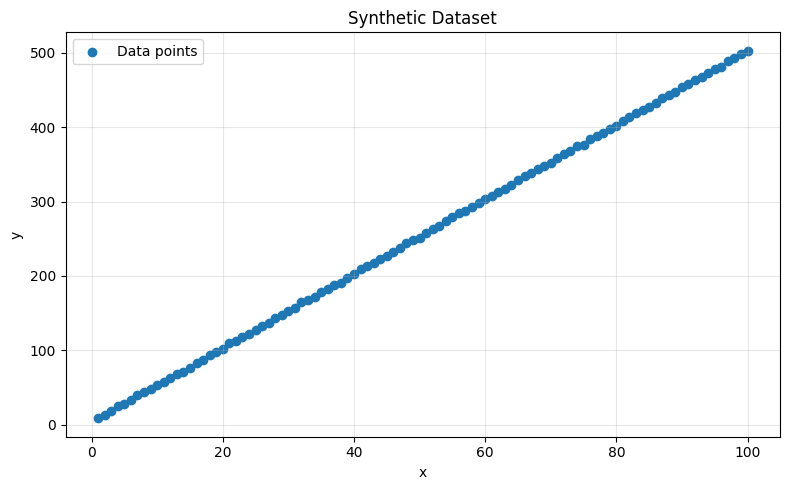


Learned parameters:
theta (processed scale) = [255.39615348 144.37056816]
Intercept = 2.825794
Slope     = 5.001393
Learned equation: y = 2.825794 + 5.001393x

Evaluation:
MSE  = 0.814905
RMSE = 0.902721
R^2  = 0.999961


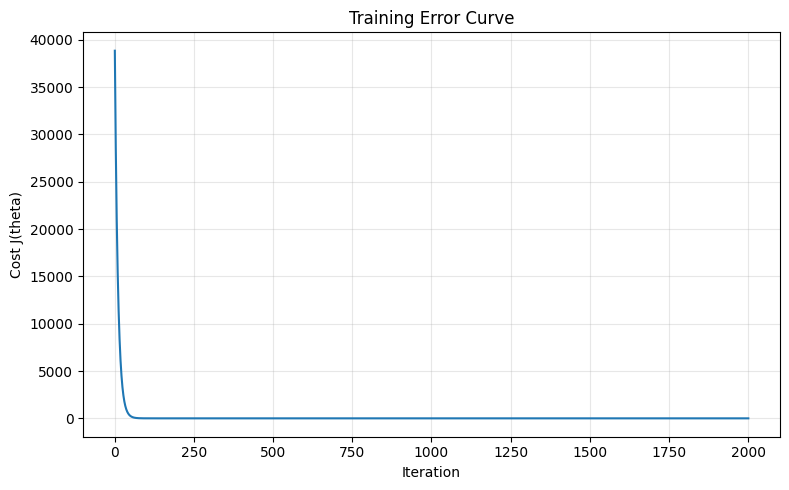

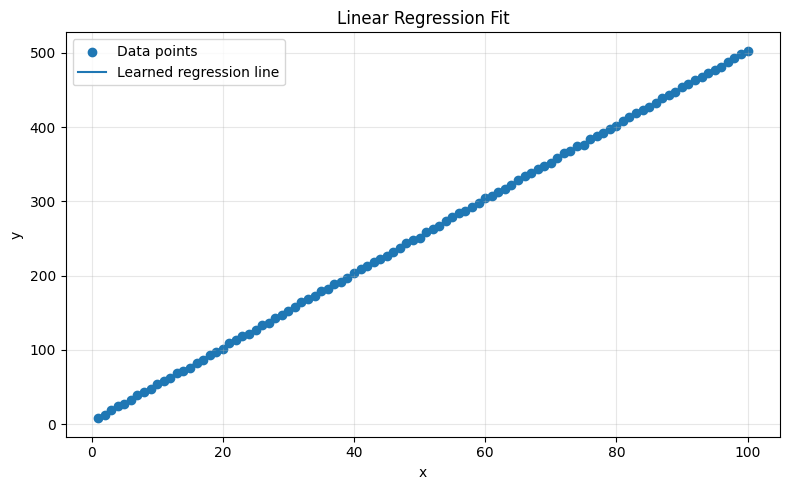

In [12]:
def main():
    x, y = load_data("dataset.csv")

    print(f"Number of samples: {len(x)}")
    plot_data(x, y)
    X, y, scaler = process_data(x, y, scale=True)
    learning_rate = 0.05
    iterations = 2000

    theta, cost_history = train(
        X,
        y,
        learning_rate=learning_rate,
        iterations=iterations
    )

    intercept, slope = convert_theta_to_original_scale(theta, scaler)

    print("\nLearned parameters:")
    print(f"theta (processed scale) = {theta}")
    print(f"Intercept = {intercept:.6f}")
    print(f"Slope     = {slope:.6f}")
    print(f"Learned equation: y = {intercept:.6f} + {slope:.6f}x")

    mse, rmse, r2 = evaluate(X, y, theta)

    print("\nEvaluation:")
    print(f"MSE  = {mse:.6f}")
    print(f"RMSE = {rmse:.6f}")
    print(f"R^2  = {r2:.6f}")

    plot_training_error(cost_history)
    plot_regression_line(x, y, intercept, slope)


if __name__ == "__main__":
    main()